есть n параметров и n значений (1 параметр - одно значение f). Итоговая релевантность = суммы параметров*значение
В вводе дается: 
(1) n - кол-во параметров (не более 100) 
(2) далее n целых чисел (каждое из которых не более 10^8)
(3) одно целое число объектов для ранжирования d (не более 100 000 и не менее 10), причем n*d не более 100 000. Здесь каждый i-тый элемент
(4) d строк, где в каждой n целых чисел f - числовые признаки i-того объекта (f не более 10^8)
(5) одно целое число q (не более 100 000) - количество запросов в системе ранжирования
(6) q строк, где в каждой 
    (или) 1 k - то есть выдать k самых релевантных объектов (k не более 10)
    (или) 2 i j v - j-признак i-того элемента становится равен v
*каждый пункт - отдельная строка или строки
В выводе:
После запроса 1 типа выводить порядковые номера k самых релевантных объектов в порядке убывания релевантности

*двух объектов с одинаковым значением релеватности нет

```
                    признак 1   признак 2
                       j=1         j=2
                   ┌───────────────────────┐
веса a             │     1          100    │   одни на всех, не меняются
                   └───────────────────────┘
                   ┌───────────────────────┐   релевантность 
объект 1   (i=1)   │     1           2     │ →  1·1  + 100·2 = 201
объект 2   (i=2)   │     2           1     │ →  1·2  + 100·1 = 102
объект 3   (i=3)   │     3           1     │ →  1·3  + 100·1 = 103
объект 4   (i=4)   │     4           1     │ →  1·4  + 100·1 = 104
   ...             │    ...         ...    │       ...
объект 10  (i=10)  │    10           1     │ →  1·10 + 100·1 = 110
                   └───────────────────────┘
                    ←── n столбцов ──→
                    d строк (сверху вниз)
```

```
2             ← n = 2 признака
1 100         ← веса: a₁ = 1, a₂ = 100
10            ← d = 10 объектов
1 2           ← объект 1:  f[1][1] = 1,  f[1][2] = 2
2 1           ← объект 2:  f[2][1] = 2,  f[2][2] = 1
3 1           ← объект 3
4 1           ← объект 4
5 1           ← объект 5
6 1           ← объект 6
7 1           ← объект 7
8 1           ← объект 8
9 1           ← объект 9
10 1          ← объект 10
4             ← q = 4 запроса
1 2           ← запрос: дай топ-2
1 10          ← запрос: дай топ-10
2 4 1 1000    ← запрос: у объекта 4 признак 1 теперь равен 1000
1 10          ← запрос: дай топ-10
```

общая логика - использовать по максимуму что написали на занятии, прикрутить функцию подсчета релевантности, добавить фунционал на то что узел теперь (релевантность, номер), чтобы сортировка была по релевантности. Подумать над заменой элемента

In [77]:
a = [3, 100]
mass = [[1, 2], [2, 1], [3, 5], [4, 1], [5, 7], [6, 8], [7, 1], [8, 1], [9, 1], [10, 1]] # следить чтобы не было повторяющихся в итоге relev
def relev(a, mass):
    lst_relev = []
    for i in mass:
        sum = 0
        cnt = 0
        for j in i:
            sum += a[cnt]*j
            cnt += 1
        lst_relev.append(sum)
    return lst_relev
relev(a, mass)

[203, 106, 509, 112, 715, 818, 121, 124, 127, 130]

In [78]:
# из AlgoMipt2026/BinaryTrees.ipynb взято

class Node:
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right


class Tree:
    def __init__(self):
        self.root = None

    def add(self, value):
        if self.root is None:
            self.root = Node(value)
            return
        curnode = self.root
        while curnode:
            if value < curnode.value:
                if curnode.left:
                    curnode = curnode.left
                else:
                    curnode.left = Node(value)
                    return
            else:
                if curnode.right:
                    curnode = curnode.right
                else:
                    curnode.right = Node(value)
                    return

    def add_rec(self, value):
        self.root = self._add(self.root, value)

    def _add(self, node, value):
        if node is not None:
            if value < node.value:
                node.left = self._add(node.left, value)
            else:
                node.right = self._add(node.right, value)
            return node
        return Node(value)

    def print_tree_rec(self):
        self._print_tree_rec(self.root)

    def _print_tree_rec(self, node):
        if node:
            print(node.value)   
            self._print_tree_rec(node.left)
            self._print_tree_rec(node.right)

    def print_tree_rec_wide(self):
        self._print_tree_rec_wide([self.root])

    def _print_tree_rec_wide(self, nodes):
        if len(nodes) == 0:
            return
        node = nodes.pop(0)
        if node:
            print(node.value)
            nodes.append(node.left)
            nodes.append(node.right)
        self._print_tree_rec_wide(nodes)

    def print_tree(self):
        if self.root is None:
            return
        spisok = [self.root]
        while len(spisok):
            curnode = spisok[-1]
            print(curnode.value)
            spisok.pop(len(spisok)-1)
            if curnode.left:
                spisok.append(curnode.left)
                print(curnode.left.value)
            if curnode.right:
                spisok.append(curnode.right)
                print(curnode.right.value)
            print('-----------')

    def height(self, node):
        if node is None:
            return 0
        hl = 0
        hr = 0
        height = 0
        spisok = [node]

        while len(spisok):
            curnode = spisok.pop(len(spisok)-1)
            if curnode:
                if curnode.left or curnode.right:
                    height += 1
                if curnode.left:
                    spisok.append([curnode.left])
                if curnode.right:
                    spisok.append([curnode.right])

        # spisok = [node.left]
        # while len(spisok):
        #     curnode = spisok.pop(0)
        #     if curnode:
        #         if curnode.left or curnode.right:
        #             hl += 1
        #         if curnode.left:
        #             spisok.append([curnode.left])
        #         if curnode.right:
        #             spisok.append([curnode.right])

        # spisok = [node.right]
        # while len(spisok):
        #     curnode = spisok.pop(0)
        #     if curnode:
        #         if curnode.left or curnode.right:
        #             hr += 1
        #         if curnode.left:
        #             spisok.append([curnode.left])
        #         if curnode.right:
        #             spisok.append([curnode.right])
        return height + 1#max(hl, hr) + 1
            
    def height_rec(self, node):
        if node is None:
            return 0
        return max(self.height_rec(node.left), self.height_rec(node.right)) + 1

    def is_balanced(self):
        if self.root:
            return self._is_balanced(self.root)
        return True

    def _is_balanced(self, node):
        if node:
            hl = self.height_rec(node.left)
            hr = self.height_rec(node.right)
            print(node.value, hl, hr)
            if abs(hl-hr) > 1:
                return False
            else:
                return self._is_balanced(node.left) and self._is_balanced(node.right)
        return True

    def balance(self):
        if self.root:
            self.root = self._balance(self.root)
        return
    
    def rotate(self, node, direction):
        if direction == 'left':
            curnode1 = node.right.left
            node.right.left = node
            curnode2 = node.right
            node.right = curnode1
            return curnode2
        else:
            curnode1 = node.left.right
            node.left.right = node
            curnode2 = node.left
            node.left = curnode1
            return curnode2
    
    def _balance(self, node):
        if node:
            node.left = self._balance(node.left)
            node.right = self._balance(node.right)

            hl = self.height_rec(node.left)
            hr = self.height_rec(node.right)  
            if hl - hr < -1:
                if self.height_rec(node.right.left) > self.height_rec(node.right.right):
                    node.right = self.rotate(node.right, 'right')
                node = self.rotate(node, 'left')
            elif hl - hr > 1:
                if self.height_rec(node.left.right) > self.height_rec(node.left.left):
                    node.left = self.rotate(node.left, 'left')
                node = self.rotate(node, 'right')
        return node

#новое для ячейки 9
    def top(self, k): 
        result = []
        self._top(self.root, k, result)
        return result

    def _top(self, node, k, result):
        if node is None or len(result) == k: # тут как раз аккуратно обходим случай, если k больше числа элементов в дереве без  
                                             # предварительной проверки на кол-во элементов в дереве 
            return 
        self._top(node.right, k, result)
        if len(result) < k:
            result.append(node.value[1])
        self._top(node.left, k, result)

# засовываем элементы массива в деревo с условием, что в дано номера объектов идут с 1, поэтому i + 1.

rel = relev(a, mass)

tree = Tree()
for i in range(len(rel)):
    tree.add((rel[i], i + 1))

tree.print_tree_rec_wide()

(203, 1)
(106, 2)
(509, 3)
(112, 4)
(715, 5)
(121, 7)
(818, 6)
(124, 8)
(127, 9)
(130, 10)


In [79]:
def show(node, depth=0):
    if node:
        show(node.right, depth + 1)
        print('      ' * depth + str(node.value))
        show(node.left, depth + 1)

In [80]:
show(tree.root)

                  (818, 6)
            (715, 5)
      (509, 3)
(203, 1)
                                    (130, 10)
                              (127, 9)
                        (124, 8)
                  (121, 7)
            (112, 4)
      (106, 2)


допишем в класс tree функции по выбору топа

In [81]:
print(tree.top(1))
print(tree.top(3))
print(tree.top(10))
print(tree.top(2000))  

[6]
[6, 5, 3]
[6, 5, 3, 1, 10, 9, 8, 7, 4, 2]
[6, 5, 3, 1, 10, 9, 8, 7, 4, 2]


дальше реализуем удаление элемента с тремя развилками
- у элемента нет детей, тогда просто удаляем и родителю в указателе ().right или ().left ставим None
- один ребенок, тогда вне зависимости от right или left ребенок становится старше
- если два ребенка, то нужно заменить на элемент, у которого либо случай один, либо два. Также должен встать в иерархию -> помимо того что в идеале бездетный, но еще максимально близкий по старшенству ИЛИ меньшенству элемент. Чтобы его найти, нужно найти минимальный среди максимальных ИЛИ максимальный среди минимальных, в иерархии дерева - это шаг вправо и максимально влево ИЛИ шаг влево и максимально вправо
Неприятный случай может быть если у итогового максимально правого среди левых будет левая дочь (дальше лево - дочь, право - сын). Но тогда мы возвращаемся к случаю 2, где один ребенок у удаляемого элемента, то есть у нас будет просто еще одно удаление. 

In [82]:
# балансировка с занятия: применяем к нынешнему дереву, дальше работаем с ним
tree.balance()
show(tree.root)

            (818, 6)
      (715, 5)
            (509, 3)
(203, 1)
                  (130, 10)
            (127, 9)
                  (124, 8)
      (121, 7)
                  (112, 4)
            (106, 2)


In [83]:
def delete(tree, value):
    # ищем удаляемый элемент и запоминаем его родителя
    parent = None
    element = tree.root
    while element.value != value:
        parent = element
        if value < element.value:
            element = element.left
        else:
            element = element.right
    daughter = element.left
    son = element.right
    # то есть по факту как таковой элемент мы не удаляем, а убираем ссылку на него от его родителя, то есть при поиске/обходе дерева,  
    # мы его не найдем
    # 1
    if daughter is None and son is None:
        child = None
    # 2
    elif son is None:
        child = daughter
    elif daughter is None:
        child = son
    # 3
    else:
        # максимально сын среди относительных дочерей
        closest = daughter
        while closest.right:
            closest = closest.right
        closest_value = closest.value
        delete(tree, closest_value) # в идеале именно тут мы отрываем элемент от древа, тк мы стремимся к идеальным случаям 1 и 2
                                    # то есть после отработанного этого блока стоит выходить, чтобы не выполнять два раза подряд одно и 
                                    # то же с ошибкой UnboundLocalError: cannot access local variable 'child' where it is not associated with a value
                                    # тк переменная child задается в вариантах 1 и 2, которые мы пропустили
        element.value = closest_value
        return
    # обозначаем ребенка удаляемого элемента относительно родителя удаляемого элемента
    if parent is None:   # случай, если удаляем корень
        tree.root = child
    elif value < parent.value:  # элемент был дочерью того кто сверху
        parent.left = child
    else:                       # элемент был сыном того кто сверху
        parent.right = child

In [84]:
import copy
tree_dlt_exmlp = copy.deepcopy(tree)
delete(tree_dlt_exmlp, (203, 1))  #пока принимает элемент как связку релевантности и знания его старой позции, потом подапрвим если надо
show(tree_dlt_exmlp.root)
print('\n\n_____________а было__________\n\n')
show(tree.root)

            (818, 6)
      (715, 5)
            (509, 3)
(130, 10)
            (127, 9)
                  (124, 8)
      (121, 7)
                  (112, 4)
            (106, 2)


_____________а было__________


            (818, 6)
      (715, 5)
            (509, 3)
(203, 1)
                  (130, 10)
            (127, 9)
                  (124, 8)
      (121, 7)
                  (112, 4)
            (106, 2)


Далее полноценно обрабатываем запрос 2 i j v

2     5     1     100
      │     │     └─ v: новое значение
      │     └─────── j: какой признак (столбец из старой схемы)
      └───────────── i: какой объект (строка из старой схемы)

С учетом наработок сделаем 
- старый элемент (пару значений) убираем delete
- обновить наш список mass с новым занчением параметров
- релевантность пересчитываем с новым значением v 
- добавить в дерево новую пару 

In [106]:
def change(tree, a, mass, rel, i, j, v):
    if mass[i - 1][j - 1] == v: # если решим повторно жмать на ячейку с заменой
        return
    delete(tree, (rel[i - 1], i)) # -1 тк дано начало с 1
    mass[i - 1][j - 1] = v
    new_rel = relev(a, [mass[i - 1]])[0]
    tree.add((new_rel, i))
    rel[i - 1] = new_rel

In [94]:
# tree_dlt_exmlp = copy.deepcopy(tree)
# mass_copy = copy.deepcopy(mass)
print(mass_copy[4], tree_dlt_exmlp.top(3))
show(tree_dlt_exmlp.root)
print('__________стало после замены параметров__________')
change(tree, a, mass, rel, 5, 1, 100)
print(mass[4], tree.top(3))     
show(tree.root)

[5, 7] [6, 5, 3]
            (818, 6)
      (715, 5)
            (509, 3)
(203, 1)
                  (130, 10)
            (127, 9)
                  (124, 8)
      (121, 7)
                  (112, 4)
            (106, 2)
__________стало после замены параметров__________
[100, 7] [5, 6, 3]
                  (1000, 5)
            (818, 6)
      (509, 3)
(203, 1)
                  (130, 10)
            (127, 9)
                  (124, 8)
      (121, 7)
                  (112, 4)
            (106, 2)


теперь напишем функцию для парсинга входных данных на три блока: веса, список mass (список множителей для каждого объекта по каждому признаку) и список запросов

In [101]:
dano = """2
1 100
10
1 2
2 1
3 1
4 1
5 1
6 1
7 1
8 1
9 1
10 1
4
1 2
1 10
2 4 1 1000
1 10
"""

# n, d и q - число признаков, число объектов и число запросов соответственно
def parsing_dano(text):
    lines = text.strip().split('\n')

    # строка 0 - это n, строка 1 - веса
    n = int(lines[0])
    a = [int(x) for x in lines[1].split()]
    if len(a) != n:
        return 'ошибка число признаков != n'
    # строка 2 - это d, дальше d строк: в каждой ровно n признаков
    d = int(lines[2])
    mass = []
    for i in range(d):
        row = [int(x) for x in lines[3 + i].split()]
        if len(row) != n:
            return 'ошибка число объектов != d'
        mass.append(row)
    # сразу за таблицей строка с q, дальше ровно q строк запросов
    q = int(lines[3 + d])
    if len(lines) != 4 + d + q:
        return 'ошибка число запросов != q'
    dos = []
    for i in range(q):
        dos.append([int(x) for x in lines[4 + d + i].split()])

    return a, mass, dos

a_dano, mass_dano, dos_dano = parsing_dano(dano)
print(a_dano)
print(mass_dano)
print(dos_dano)

[1, 100]
[[1, 2], [2, 1], [3, 1], [4, 1], [5, 1], [6, 1], [7, 1], [8, 1], [9, 1], [10, 1]]
[[1, 2], [1, 10], [2, 4, 1, 1000], [1, 10]]


In [107]:
def result2_bitree(text):
    a, mass, dos = parsing_dano(text)
    rel = relev(a, mass)
    tree = Tree()
    for i in range(len(rel)):
        tree.add((rel[i], i + 1))
    for do in dos:
        if do[0] == 1:
            line = ''
            for number in tree.top(do[1]):
                line += str(number) + ' '
            print(line)
        else:
            change(tree, a, mass, rel, do[1], do[2], do[3])


result2_bitree(dano)

1 10 
1 10 9 8 7 6 5 4 3 2 
4 1 10 9 8 7 6 5 3 2 


как и в файле 

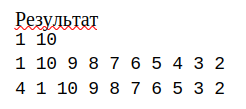

## Задача 3 балансировка красно черного дерева

In [6]:
class Node:  # добавил степень описания ноды - цвет, базово для добавляющейся ноды - красный, детей None/Nih
    def __init__(self, value, left=None, right=None, color='red'):
        self.value = value
        self.left = left
        self.right = right
        self.color = color

class RBtree:  # заготовка из семинарского RBtree.ipynb
    def __init__(self):
        self.root = None
    def append(self, value): # рекурсивная вставка из 2 задачи
        self.root = self._append(self.root, value)
        self.root.color = 'black'
    def _append(self, node, value):
        if node is None:
            return Node(value)
        if value > node.value:
            node.right = self._append(node.right, value)
        else:
            node.left = self._append(node.left, value)
        return node
    
    def rotate(self, node, direction): # готовая реализация Tree.rotate из задачи 2
        if direction == 'left':
            curnode1 = node.right.left
            node.right.left = node
            curnode2 = node.right
            node.right = curnode1
            return curnode2
        else:
            curnode1 = node.left.right
            node.left.right = node
            curnode2 = node.left
            node.left = curnode1
            return curnode2

In [7]:
# чуть измененный show из задаче 2
def show_rb(node, depth=0):
    if node:
        show_rb(node.right, depth + 1)
        color = 'чёрный' if node.color == 'black' else 'красный'
        print('      ' * depth + f'{node.value} ({color})')
        show_rb(node.left, depth + 1)


rbtree = RBtree()
rbtree2 = RBtree()
for i in (1, 2, 3 , 4 , 5):
    rbtree.append(i)

show_rb(rbtree.root)
print('_________________\n')
for i in (5,4,3,2,1):
    rbtree2.append(i)

show_rb(rbtree2.root)

                        5 (красный)
                  4 (красный)
            3 (красный)
      2 (красный)
1 (чёрный)
_________________

5 (чёрный)
      4 (красный)
            3 (красный)
                  2 (красный)
                        1 (красный)


первоисточник - https://habr.com/ru/companies/otus/articles/472040/

это нужно балансировать, но дальше будет рассмотрена балансировка не целого уже построенного дерева, а балансировка, что будет происходить каждый раз при добавлении элемента. От сюда же сразу упрощение для представления механизма - работаем лишь с низами дерева и их окрестностью, не пытаемся крутить внутренности дерева

принцип при append ноды:
0) проверяем цвет родителя - если черный, то ок, добавляем всегда красный (тк смотрим высоту по черным, добавление красного - безопасно). Если красный - то не ок, тк два подряд быть не может. 
1) смотрим на брата/сестру родителя. Если тоже красные, как и родители. То просто перекрашиваем дядю/тетю и родителей в черные 
          
          root(B) <-он точно должен быть черный (тк дети красные), дальше это аукнется
         /    \
      P(R)    U(R)дядя 
      /         
    NodeNewНаш(R)

            ИЛИ

          root(B)
         /    \
      U(R)    P(R)
       тетя     \
       слева     NodeNewНаш(R)

стало 

             root(B)
            /    \
         P(B)    U(B)
         /
       N(R)

суммарное число черных стало на каждую ветвь всего дерева на 1 больше, НО может быть так, что наше дерево есть поддерево одной из ветвей большого дерева - тогда балансировка приведет к внешнему дисбалансу на +1 черной высоты с нашей стороны (стороны, где добавляем элемент)

             ROOT
            /     \
         root(B)   кто-то(B)
        /    \
    P(B)    U(B)
    /
N(R)
Потому также красим наш root в красный, получаем 
             ROOT
            /     \
         root(R)   кто-то(B)
        /    \
    P(B)    U(B)
    /
N(R)
или конкретно для нашего дерева
             root(R)
            /    \
         P(B)    U(B)
         /
       N(R)

А ВДРУГ ROOT тоже красный? это отлично решится после рассмотрения двух других случаев. Но сойдемся, что и тетю, и дядю называем просто дядя

2) Черный дядя и значение нашей новой ноды больше родителя, но меньше root (P < N < root,  root-P-N образуют угол, не лежат по прямой)
           root(B)
          /    \
        P(R)   U(B)
           \
           N(R)
Тут все также родитель красный, но дядя теперь вдруг черный. Выглядит несбалансировано изначально, но такое может быть в варианте
            root(B)
           /    \
         P(R)   NIL(B)
        /   \
    NIL(B)  N(R)
           /    \
       NIL(B)  NIL(B)

В такой раскладке мы все также имеем проблему двух подряд R, но теперь просто переккраска дяди не подойдет, тк мы испортим гармонию черного. ПОТОМУ двигаем нашу новую ноду влево за место родителя (левый поворот вокруг P) 
       root(B)
      /
    P(R)
       \
       N(R)
       
       СТАЛО

       root(B)
      /
    N(R)
    /
  P(R)

R все равно идет после R, но это вопрос для 3 варианта, к которому мы и стремились

3) дядя черный, вершины расположены в линию. Еще раз
Было дерево 
           root(B)
          /    \
        P(R)   NIL(B)
       /   \
    NIL(B)  NIL(B)

добавили нашу ноду N < P < root

           root(B)
          /    \
        P(R)   NIL(B)
       /   \
     N(R)  NIL(B)
    /    \
  NIL(B)  NIL(B)

Теперь есть красный после красного и дисбаланс черного

упрощенно без нигилизма

          root(B)
         /
       P(R)
       /
     N(R)

смещаем N вправо за место P со смещением root (правый поворот)

          root(R)
         /    \
       N(R)   G(B)
    
Теперь перекрашиваем 

          P(B)
         /    \
       N(R)   G(R)

* для логики описания справа все абсолютно также 
* выше я писал "А ВДРУГ ROOT тоже красный? это отлично решится после рассмотрения двух других случаев. Но сойдемся, что и тетю, и дядю называем просто дядя". Вспомним на чем остановились:

             ROOT(R) <-- а вдруг выше родителя тоже красно?
            /     \
         root(R)   кто-то(B)
        /    \
    P(B)    U(B)
    /
N(R)

тогда наш ROOT точно не корень всего дерева, тк корень всего дерева только черный. Ищем родителя ROOT

                  parent(B)
                 /    \
             ROOT(R)   кто-то(B или R)
             /
         root(R)
         /    \
       P(B)   U(B)
       /
     N(R)

И теперь мы смотрим на ситуацию от root - у нас родитель красный и дядя либо красный (1случай), либо черный (2 и 3 случаи).

In [ ]:
class BalancedRBtree(RBtree):
    def _append(self, node, value): # после вставки из RBtree каждый раз балансируем поддерево на обратном ходе рекурсии
        node = super()._append(node, value)
        return self._balance(node)

    def _is_red(self, node):
        return node is not None and node.color == 'red'

    def _has_red_pair(self, parent):
        if not self._is_red(parent): # для красной пары родитель должен быть красным
            return False
        return self._is_red(parent.left) or self._is_red(parent.right)

    def _balance(self, root):
        if root.color == 'red': # красную пару исправляем на уровне чёрного корня поддерева
            return root

        left = root.left
        right = root.right
        if self._has_red_pair(left):
            pair_on_left = True
        elif self._has_red_pair(right):
            pair_on_left = False
        else: # красной пары нет
            return root

        if self._is_red(left) and self._is_red(right): # красные родитель и дядя
            left.color = 'black'
            right.color = 'black'
            root.color = 'red'
            return root

        if pair_on_left: # красная пара слева, дядя чёрный или NIL
            if self._is_red(left.right): # выпрямляем угол слева
                root.left = self.rotate(left, 'left')
            new_root = self.rotate(root, 'right')
        else: # красная пара справа, дядя чёрный или NIL
            if self._is_red(right.left): # выпрямляем угол справа
                root.right = self.rotate(right, 'right')
            new_root = self.rotate(root, 'left')

        new_root.color = 'black'
        root.color = 'red'
        return new_root

In [ ]:
tests = {
    'пустое дерево': (),
    'прямо': (3, 2, 1),
    'обратно': (1, 2, 3),
    'угол слева': (3, 1, 2),
    'угол справа': (1, 3, 2),
    'красный дядя': (1, 2, 3, 4),
    'просто по возрастающей': range(1, 33),
    'повторяющиеся ноды': (2, 2, 1, 2, 3, 1),
}

In [ ]:
demo_tree = BalancedRBtree()
for value in tests['красный дядя']:
    demo_tree.append(value)
    print(f'После вставки {value}')
    show_rb(demo_tree.root)
    print()

После вставки 1
1 (чёрный)

После вставки 2
      2 (красный)
1 (чёрный)

После вставки 3
      3 (красный)
2 (чёрный)
      1 (красный)

После вставки 4
            4 (красный)
      3 (чёрный)
2 (чёрный)
      1 (чёрный)

